In [78]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering

In [3]:
df = pd.read_csv(r"C:\Users\harsh\Downloads\diabetes_risk.csv")
df.sample(5)

,patient_id,age,gender,city,bmi,family_history_diabetes,physical_activity_level,diet_type,smoking_status,alcohol_consumption,hours_sleep_per_night,stress_level,fasting_blood_sugar,hba1c_level,blood_pressure_systolic,blood_pressure_diastolic,waist_circumference_cm,income_bracket,diabetes_risk
11553,11554,41,Female,Hyderabad,17.8,Yes,Active,Vegetarian,Former,Occasional,6.6,7,171,7.3,140,96,80.8,Middle,Low
3307,3308,46,Female,Jaipur,24.0,No,Moderate,Vegetarian,Former,Occasional,9.0,7,146,6.4,140,80,100.4,Middle,Low
5364,5365,57,Female,Jaipur,27.1,Yes,Moderate,Non-Vegetarian,Never,Never,8.0,3,179,7.1,126,84,108.0,Middle,Low
2628,2629,44,Female,Bengaluru,22.3,No,Sedentary,Non-Vegetarian,Never,NaN,7.0,9,174,6.6,140,90,88.5,High,Moderate
1739,1740,26,Male,Delhi,31.0,Yes,Moderate,Vegetarian,Current,Occasional,7.0,6,240,8.4,140,90,127.8,Middle,Moderate


In [4]:
df.shape

(15000, 19)

In [5]:
df['patient_id'].duplicated().sum()

np.int64(0)

In [6]:
df['city'].unique()

array(['Mumbai', 'Thane', 'Bengaluru', 'Hyderabad', 'Delhi', 'Kolkata',
       'Ahmedabad', 'Pune', 'Chennai', 'Kanpur', 'Bhopal',
       'Visakhapatnam', 'Patna', 'Jaipur', 'Surat', 'Nagpur', 'Indore',
       'Lucknow'], dtype=object)

In [7]:
df.isnull().mean()*100

patient_id                   0.000000
age                          0.000000
gender                       0.000000
city                         0.000000
bmi                          0.000000
family_history_diabetes      0.000000
physical_activity_level      0.000000
diet_type                    0.000000
smoking_status               3.146667
alcohol_consumption         25.253333
hours_sleep_per_night        0.000000
stress_level                 0.000000
fasting_blood_sugar          0.000000
hba1c_level                  0.000000
blood_pressure_systolic      0.000000
blood_pressure_diastolic     0.000000
waist_circumference_cm       0.000000
income_bracket               3.086667
diabetes_risk                0.000000
dtype: float64

In [8]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_percentage.sort_values(ascending=False)

alcohol_consumption         25.253333
smoking_status               3.146667
income_bracket               3.086667
hours_sleep_per_night        0.000000
waist_circumference_cm       0.000000
blood_pressure_diastolic     0.000000
blood_pressure_systolic      0.000000
hba1c_level                  0.000000
fasting_blood_sugar          0.000000
stress_level                 0.000000
patient_id                   0.000000
age                          0.000000
diet_type                    0.000000
physical_activity_level      0.000000
family_history_diabetes      0.000000
bmi                          0.000000
city                         0.000000
gender                       0.000000
diabetes_risk                0.000000
dtype: float64

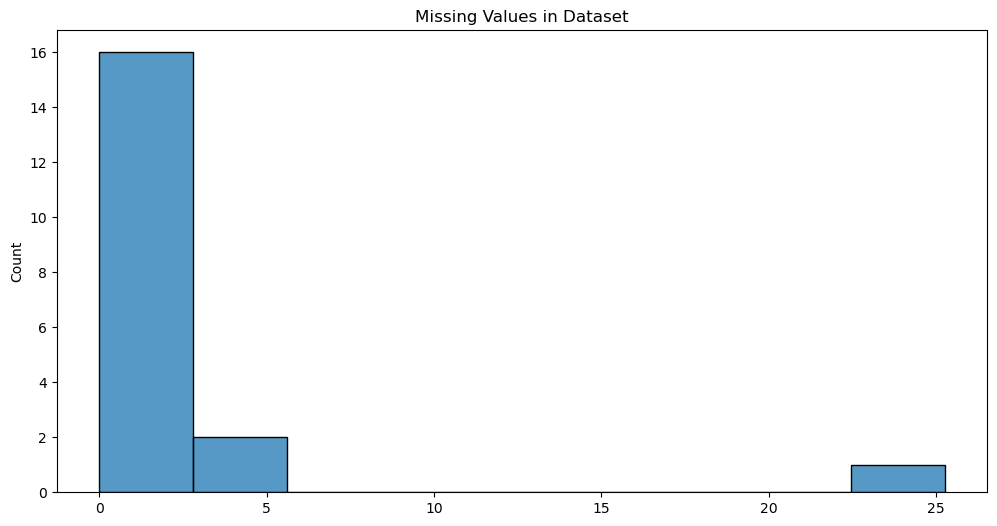

In [9]:
plt.figure(figsize=(12, 6))

sns.histplot(missing_percentage, cbar=False)

plt.title("Missing Values in Dataset")
plt.show()

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
for column in df.select_dtypes(include='object').columns:
    print("\n",column)
    print(df[column].unique())
    


 gender
['Female' 'Male' 'Other']

 city
['Mumbai' 'Thane' 'Bengaluru' 'Hyderabad' 'Delhi' 'Kolkata' 'Ahmedabad'
 'Pune' 'Chennai' 'Kanpur' 'Bhopal' 'Visakhapatnam' 'Patna' 'Jaipur'
 'Surat' 'Nagpur' 'Indore' 'Lucknow']

 family_history_diabetes
['Yes' 'No']

 physical_activity_level
['Sedentary' 'Moderate' 'Active']

 diet_type
['Vegetarian' 'Non-Vegetarian' 'Pescatarian' 'Vegan']

 smoking_status
['Never' 'Current' nan 'Former']

 alcohol_consumption
['Never' 'Regular' 'Occasional' nan]

 income_bracket
['High' 'Low' 'Middle' nan]

 diabetes_risk
['Low' 'High' 'Moderate']


In [31]:
numerical_cols = df.select_dtypes(include=np.number).columns

categorical_columns = df.select_dtypes(include="object").columns

print("Numerical columns:")
print(numerical_cols)

print("\nCategorical columns:")
print(categorical_columns)

Numerical columns:
Index(['patient_id', 'age', 'bmi', 'hours_sleep_per_night', 'stress_level',
       'fasting_blood_sugar', 'hba1c_level', 'blood_pressure_systolic',
       'blood_pressure_diastolic', 'waist_circumference_cm'],
      dtype='object')

Categorical columns:
Index(['gender', 'city', 'family_history_diabetes', 'physical_activity_level',
       'diet_type', 'smoking_status', 'alcohol_consumption', 'income_bracket',
       'diabetes_risk'],
      dtype='object')


In [32]:
df["patient_id"].nunique()

15000

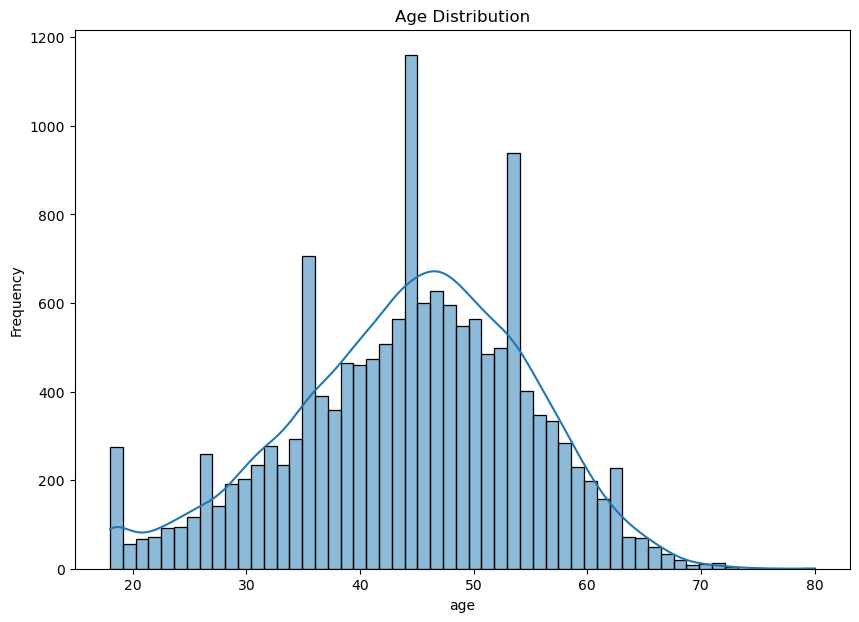

In [14]:
plt.figure(figsize=(10,7))

sns.histplot(df['age'],kde=True)

plt.title("Age Distribution")
plt.xlabel("age")
plt.ylabel("Frequency")

plt.show()

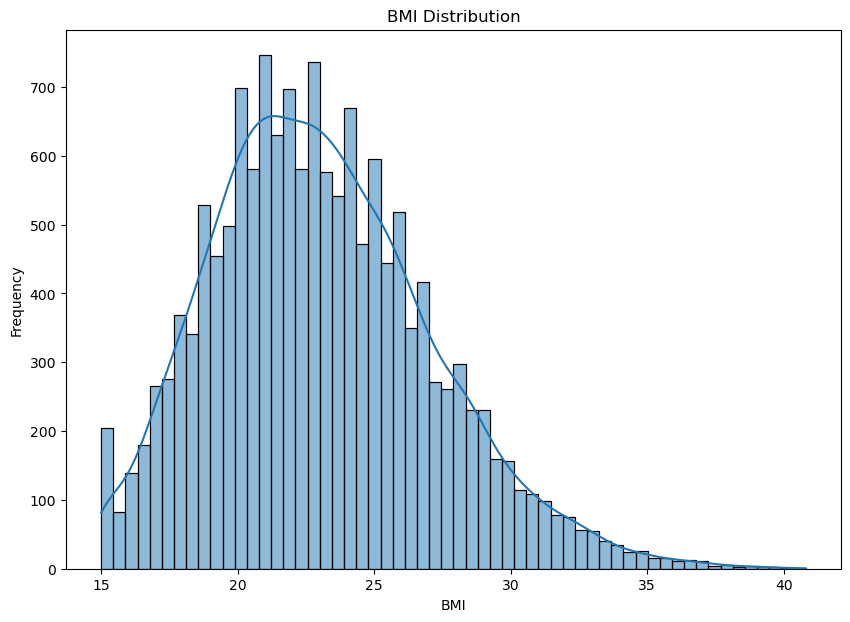

In [15]:
plt.figure(figsize=(10,7))

sns.histplot(df['bmi'],kde=True)

plt.title("BMI Distribution")
plt.xlabel("BMI")
plt.ylabel("Frequency")

plt.show()

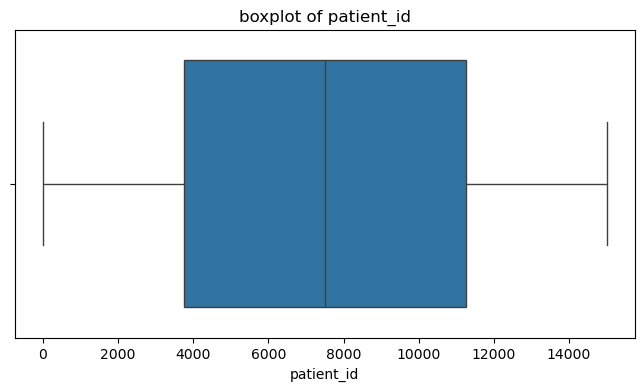

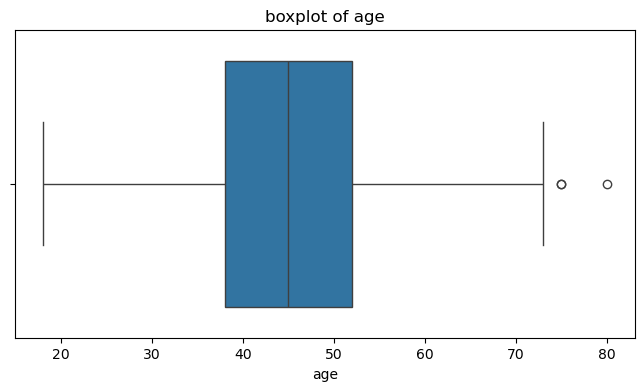

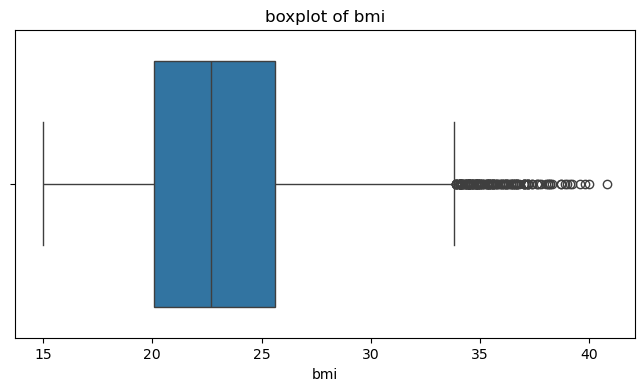

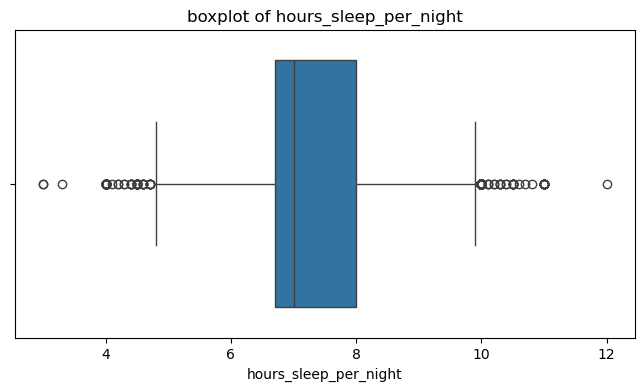

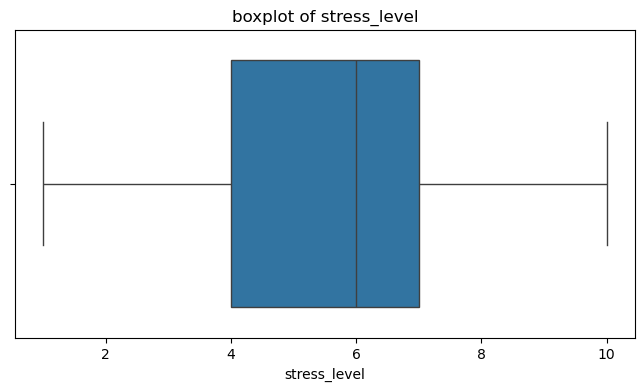

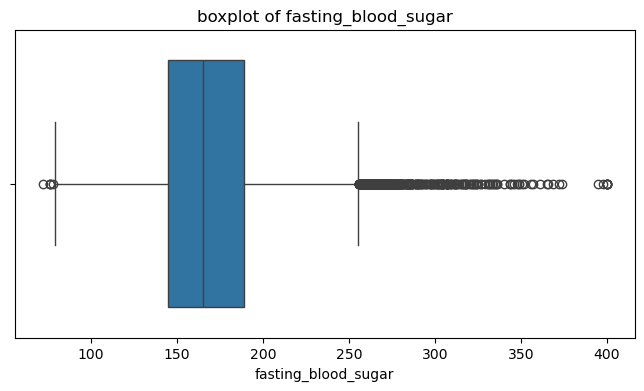

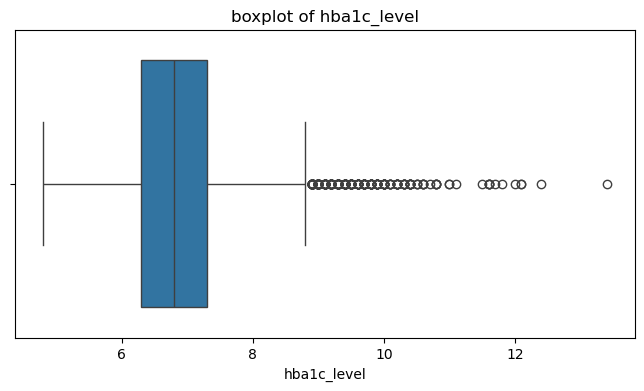

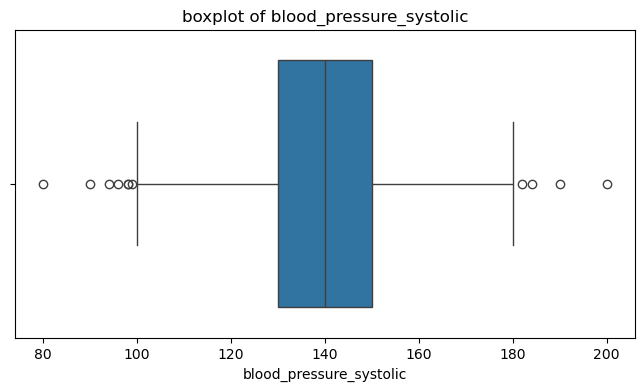

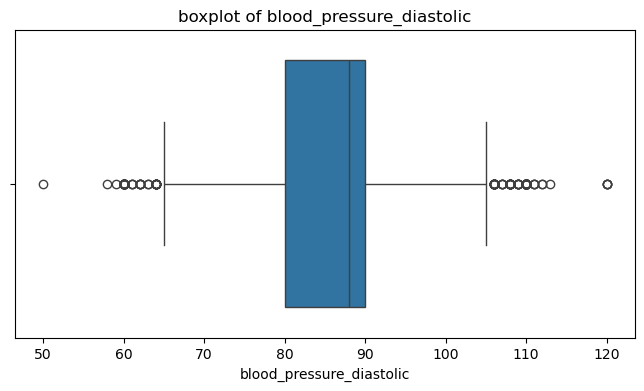

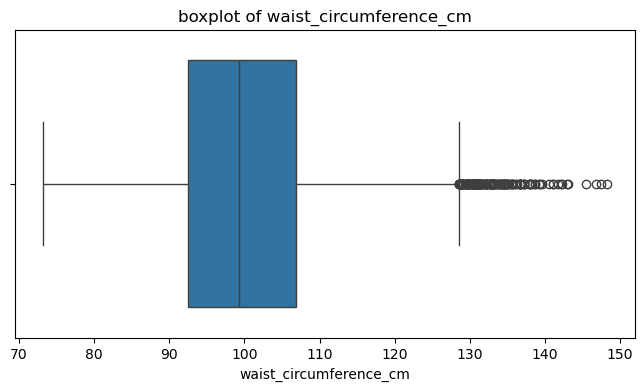

In [16]:
for column in numerical_columns:
    plt.figure(figsize=(8,4))
    sns.boxplot(x=df[column])
    plt.title(f"boxplot of {column}")
    plt.show()

In [33]:
from sklearn.preprocessing import StandardScaler
numerical_cols = [col for col in numerical_cols if col != 'patient_id']

scaler = StandardScaler()


numerical_scaled = scaler.fit_transform(df[numerical_columns])

numerical_df = pd.DataFrame(
    numerical_scaled,
    columns=numerical_columns,
    index=df.index
)

numerical_df.head()

,patient_id,age,bmi,hours_sleep_per_night,stress_level,fasting_blood_sugar,hba1c_level,blood_pressure_systolic,blood_pressure_diastolic,waist_circumference_cm
0,-1.731935,0.256788,0.849610,1.523561,0.958324,0.240067,0.499987,0.513714,0.446334,0.640528
1,-1.731704,0.834633,-0.633242,-0.279320,0.027370,-0.437642,0.025631,1.303580,1.638762,-0.595534
2,-1.731473,0.256788,2.035892,-0.279320,0.492847,-0.020590,-0.330136,0.829660,1.877248,1.235325
3,-1.731243,-0.321057,-0.064815,1.523561,-0.438107,-0.359445,-0.211547,-1.066020,0.684819,0.872871
4,-1.731012,1.219863,-1.572382,-0.730041,1.889277,0.500724,-0.211547,-0.750073,0.446334,-1.803716


In [34]:


categorical_cols = [
    "gender",
    "physical_activity_level",
    "diet_type",
    "smoking_status",
    "alcohol_consumption",
    "income_bracket"
]


encoder = OneHotEncoder(
    drop="first",
    sparse_output=False
)


encoded_data = encoder.fit_transform(df[categorical_cols])


encoded_df = pd.DataFrame(
    encoded_data,
    columns=encoder.get_feature_names_out(categorical_cols),
    index=df.index
)


numerical_cols = df.select_dtypes(
    include=["int64", "float64"]
).columns

numerical_cols = [col for col in numerical_cols if col != 'patient_id']

scaler = StandardScaler()


numerical_scaled = scaler.fit_transform(df[numerical_cols])

numerical_df = pd.DataFrame(
    numerical_scaled,
    columns=numerical_cols,
    index=df.index
)



cluster_data = pd.concat(
    [numerical_df, encoded_df],
    axis=1
)
cluster_data.head()

,age,bmi,hours_sleep_per_night,stress_level,fasting_blood_sugar,hba1c_level,blood_pressure_systolic,blood_pressure_diastolic,waist_circumference_cm,gender_Male,...,diet_type_Vegetarian,smoking_status_Former,smoking_status_Never,smoking_status_nan,alcohol_consumption_Occasional,alcohol_consumption_Regular,alcohol_consumption_nan,income_bracket_Low,income_bracket_Middle,income_bracket_nan
0,0.256788,0.849610,1.523561,0.958324,0.240067,0.499987,0.513714,0.446334,0.640528,0.0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.834633,-0.633242,-0.279320,0.027370,-0.437642,0.025631,1.303580,1.638762,-0.595534,0.0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,0.256788,2.035892,-0.279320,0.492847,-0.020590,-0.330136,0.829660,1.877248,1.235325,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
3,-0.321057,-0.064815,1.523561,-0.438107,-0.359445,-0.211547,-1.066020,0.684819,0.872871,1.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,1.219863,-1.572382,-0.730041,1.889277,0.500724,-0.211547,-0.750073,0.446334,-1.803716,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


C:\Users\harsh\AppData\Local\Temp\ipykernel_21492\1673321789.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['hours_sleep_per_night'])
C:\Users\harsh\AppData\Local\Temp\ipykernel_21492\1673321789.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['stress_level'])


<Axes: xlabel='stress_level', ylabel='Density'>

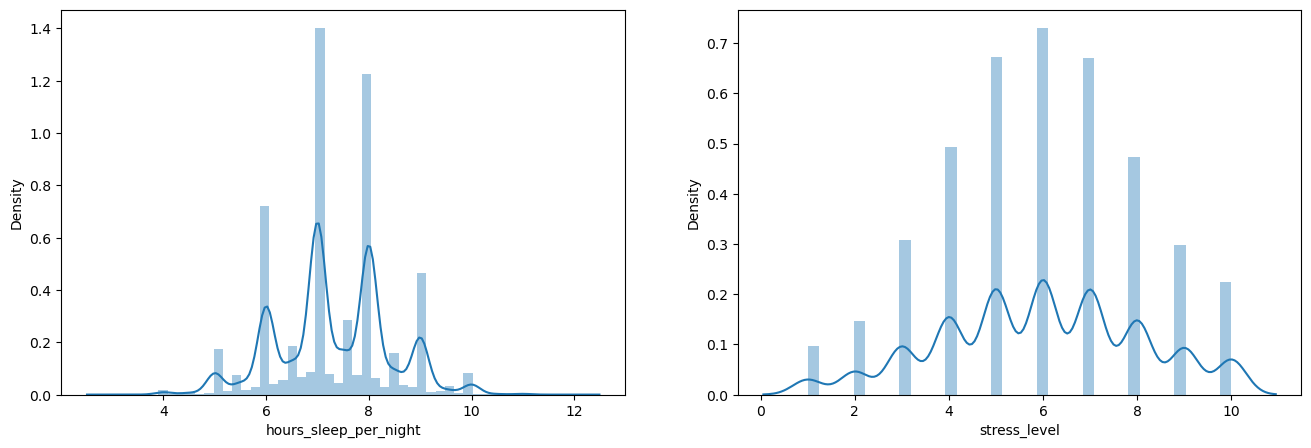

In [18]:
plt.figure(figsize=(16,5))
plt.subplot(1,2,1)
sns.distplot(df['hours_sleep_per_night'])

plt.subplot(1,2,2)
sns.distplot(df['stress_level'])



C:\Users\harsh\AppData\Local\Temp\ipykernel_21492\2873783037.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['fasting_blood_sugar'])
C:\Users\harsh\AppData\Local\Temp\ipykernel_21492\2873783037.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['hba1c_level'])


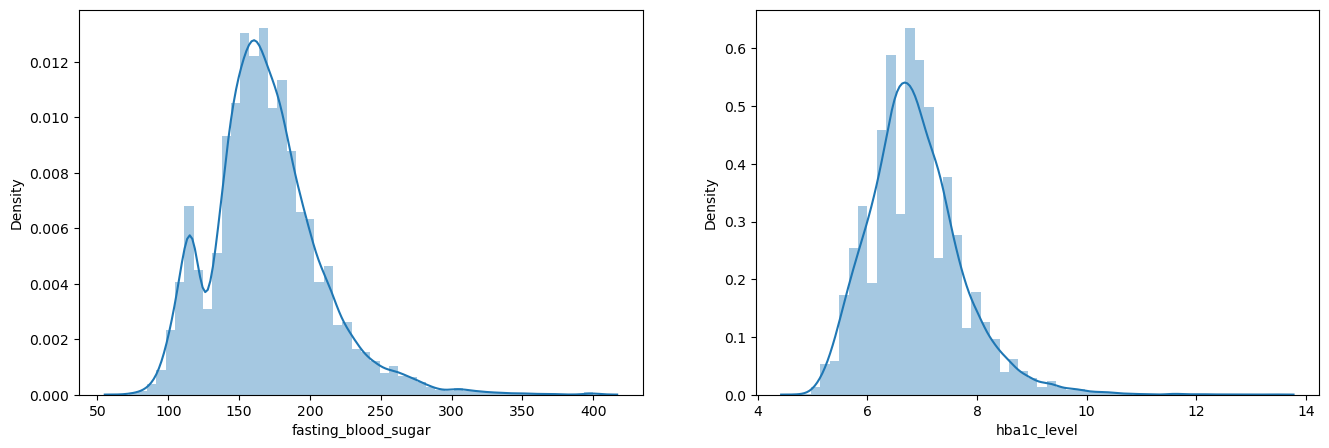

In [19]:
plt.figure(figsize=(16,5))
plt.subplot(1,2,1)
sns.distplot(df['fasting_blood_sugar'])

plt.subplot(1,2,2)
sns.distplot(df['hba1c_level'])


plt.show()

C:\Users\harsh\AppData\Local\Temp\ipykernel_21492\2567230724.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['blood_pressure_systolic'])
C:\Users\harsh\AppData\Local\Temp\ipykernel_21492\2567230724.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['blood_pressure_diastolic'])


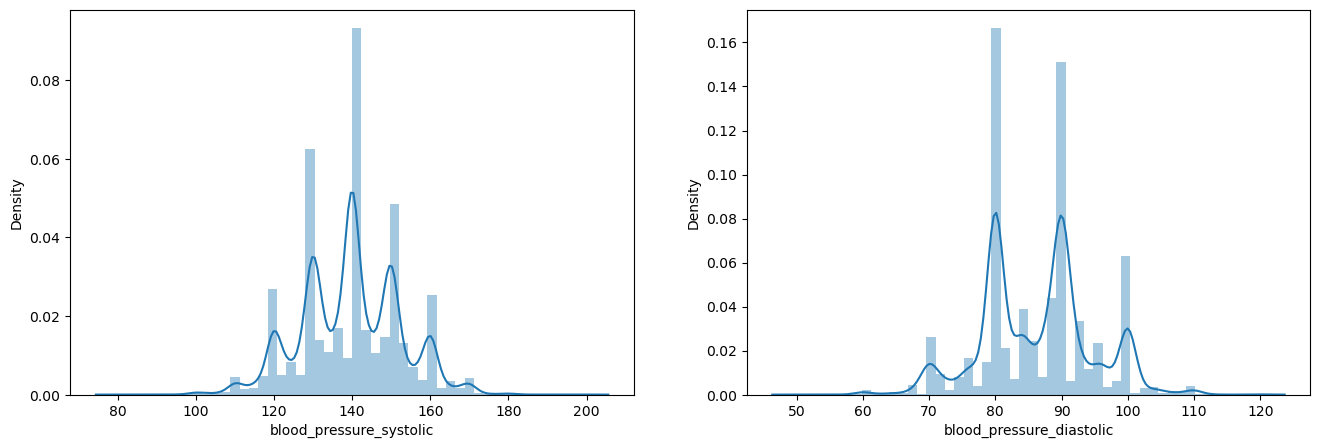

In [20]:
plt.figure(figsize=(16,5))
plt.subplot(1,2,1)
sns.distplot(df['blood_pressure_systolic'])

plt.subplot(1,2,2)
sns.distplot(df['blood_pressure_diastolic'])

plt.show()

C:\Users\harsh\AppData\Local\Temp\ipykernel_21492\3817708167.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['waist_circumference_cm'])


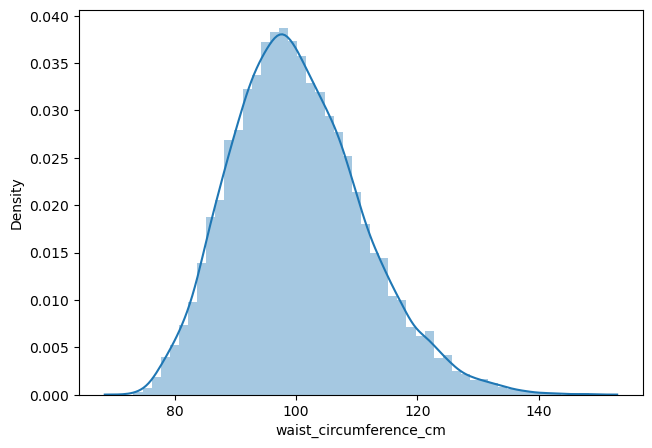

In [21]:
plt.figure(figsize=(16,5))
plt.subplot(1,2,1)
sns.distplot(df['waist_circumference_cm'])
plt.show()

In [22]:
df['hours_sleep_per_night'].describe()

count    15000.000000
mean         7.309860
std          1.109372
min          3.000000
25%          6.700000
50%          7.000000
75%          8.000000
max         12.000000
Name: hours_sleep_per_night, dtype: float64

In [23]:
hspn_mean=df['hours_sleep_per_night'].mean()
hspn_std=df['hours_sleep_per_night'].std()


In [24]:
df['diabetes_risk'].unique()

array(['Low', 'High', 'Moderate'], dtype=object)

In [25]:
df

,patient_id,age,gender,city,bmi,family_history_diabetes,physical_activity_level,diet_type,smoking_status,alcohol_consumption,hours_sleep_per_night,stress_level,fasting_blood_sugar,hba1c_level,blood_pressure_systolic,blood_pressure_diastolic,waist_circumference_cm,income_bracket,diabetes_risk
0,1,47,Female,Mumbai,26.5,Yes,Sedentary,Vegetarian,Never,Never,9.0,8,178,7.3,146,90,107.1,High,Low
1,2,53,Female,Mumbai,20.5,Yes,Moderate,Vegetarian,Never,Never,7.0,6,152,6.9,156,100,93.8,Low,Low
2,3,47,Male,Thane,31.3,No,Moderate,Non-Vegetarian,Current,Regular,7.0,7,168,6.6,150,102,113.5,Low,High
3,4,41,Male,Bengaluru,22.8,No,Sedentary,Non-Vegetarian,Never,Never,9.0,5,155,6.7,126,92,109.6,Middle,Low
4,5,57,Female,Bengaluru,16.7,No,Sedentary,Non-Vegetarian,Current,Occasional,6.5,10,188,6.7,130,90,80.8,High,Low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14995,14996,47,Male,Mumbai,37.7,No,Sedentary,Non-Vegetarian,Never,Never,6.8,7,213,8.1,150,100,141.7,High,High
14996,14997,48,Female,Mumbai,20.6,No,Moderate,Non-Vegetarian,Never,NaN,6.0,8,162,6.5,132,80,91.0,NaN,Low
14997,14998,34,Female,Nagpur,17.9,No,Active,Vegetarian,Never,Never,7.0,6,137,6.5,136,90,88.8,Low,Low
14998,14999,56,Male,Ahmedabad,20.7,Yes,Active,Vegetarian,Never,Never,6.0,5,163,6.9,140,87,94.8,Low,Low


In [26]:
tm_df=df.iloc[:, 10:19]
tm_df

,hours_sleep_per_night,stress_level,fasting_blood_sugar,hba1c_level,blood_pressure_systolic,blood_pressure_diastolic,waist_circumference_cm,income_bracket,diabetes_risk
0,9.0,8,178,7.3,146,90,107.1,High,Low
1,7.0,6,152,6.9,156,100,93.8,Low,Low
2,7.0,7,168,6.6,150,102,113.5,Low,High
3,9.0,5,155,6.7,126,92,109.6,Middle,Low
4,6.5,10,188,6.7,130,90,80.8,High,Low
...,...,...,...,...,...,...,...,...,...
14995,6.8,7,213,8.1,150,100,141.7,High,High
14996,6.0,8,162,6.5,132,80,91.0,NaN,Low
14997,7.0,6,137,6.5,136,90,88.8,Low,Low
14998,6.0,5,163,6.9,140,87,94.8,Low,Low


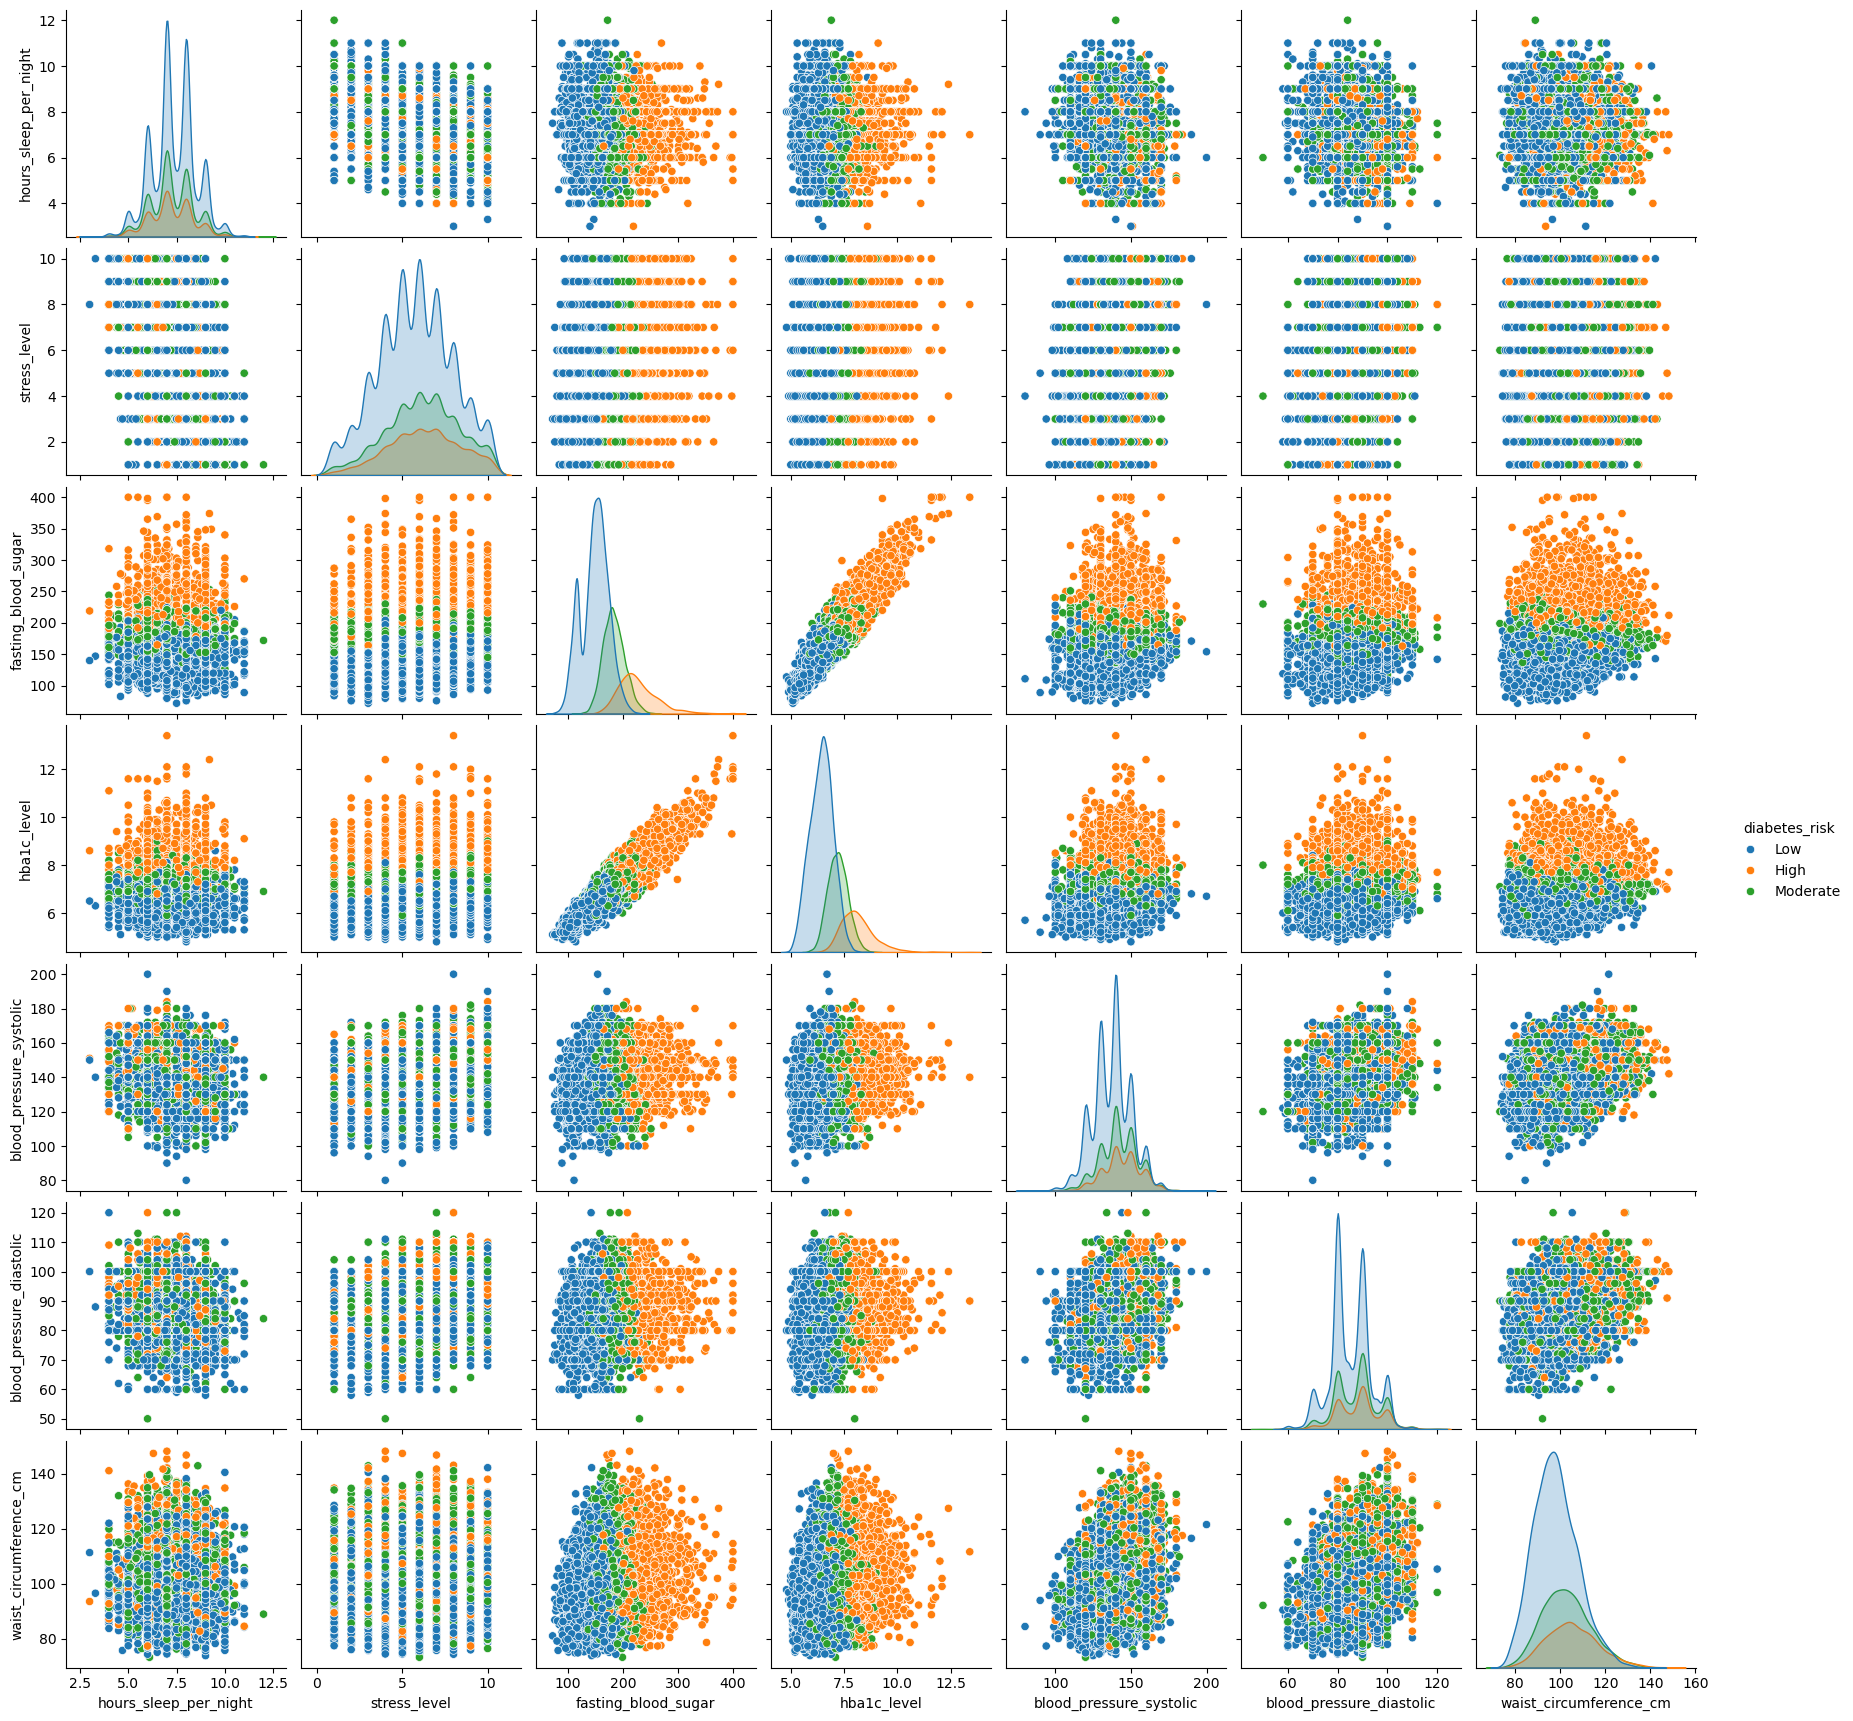

In [40]:
sns.pairplot(tm_df,hue='diabetes_risk')

In [36]:
X_scaled=cluster_data

In [37]:
inertia = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(X_scaled)
    
    inertia.append(kmeans.inertia_)

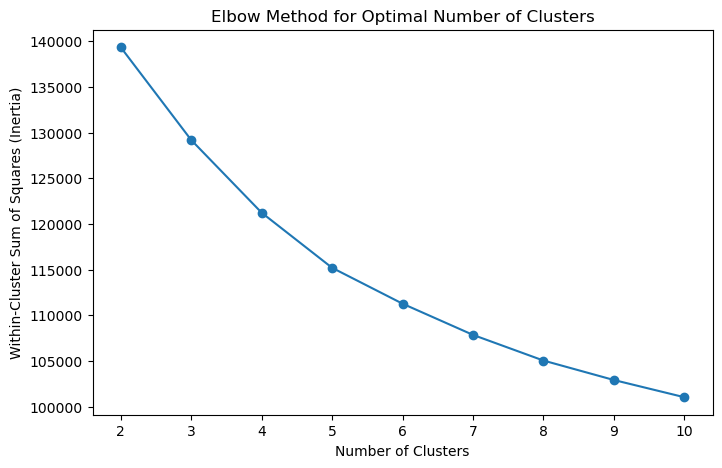

In [38]:
plt.figure(figsize=(8, 5))

plt.plot(range(2, 11), inertia, marker="o")

plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters")
plt.ylabel("Within-Cluster Sum of Squares (Inertia)")

plt.show()

In [39]:
silhouette_scores = []

for k in range(2, 11):
    
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    labels = kmeans.fit_predict(X_scaled)
    
    score = silhouette_score(X_scaled, labels)
    
    silhouette_scores.append(score)

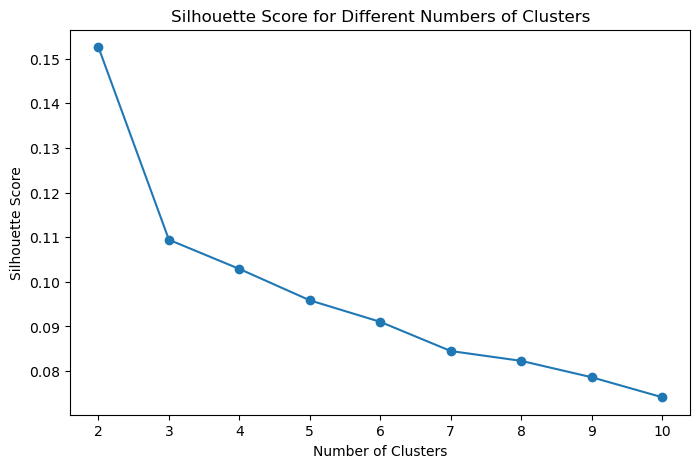

In [40]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker="o"
)

plt.title("Silhouette Score for Different Numbers of Clusters")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")

plt.show()

In [50]:
best_k = range(2, 11)[np.argmax(silhouette_scores)]

print("Best K based on Silhouette Score:", best_k)

Best K based on Silhouette Score: 2


In [51]:
optimal_k=2
kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)

In [52]:
df["Cluster"] = clusters
df["Cluster"].value_counts().sort_index()

Cluster
0    7044
1    7956
Name: count, dtype: int64

In [53]:
cluster_profile = df.groupby("Cluster").mean(numeric_only=True)

cluster_profile

,patient_id,age,bmi,hours_sleep_per_night,stress_level,fasting_blood_sugar,hba1c_level,blood_pressure_systolic,blood_pressure_diastolic,waist_circumference_cm
Cluster,,,,,,,,,,
0,7492.273992,49.066298,25.712862,7.134228,6.503265,189.291312,7.312351,146.297984,90.062606,107.081161
1,7507.783057,40.143539,20.715498,7.465359,5.443565,150.638638,6.494168,133.474108,82.887506,94.122587


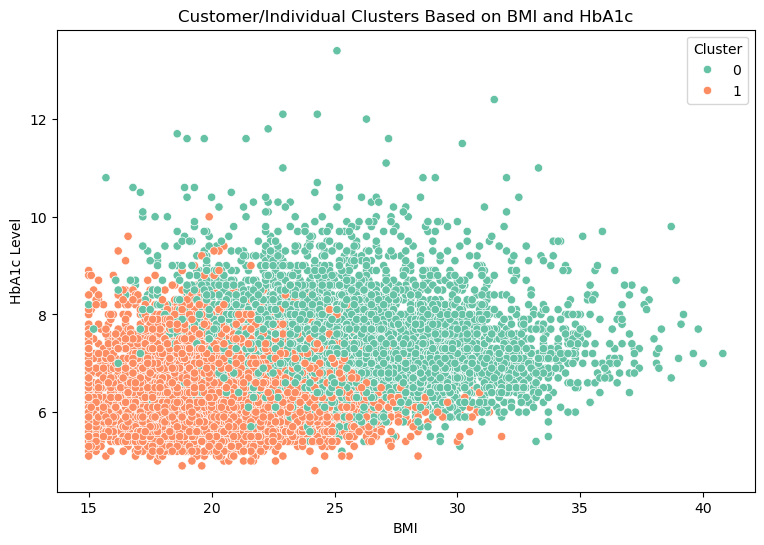

In [54]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="bmi",
    y="hba1c_level",
    hue="Cluster",
    palette="Set2"
)

plt.title("Customer/Individual Clusters Based on BMI and HbA1c")
plt.xlabel("BMI")
plt.ylabel("HbA1c Level")

plt.show()

<Axes: xlabel='hours_sleep_per_night', ylabel='blood_pressure_systolic'>

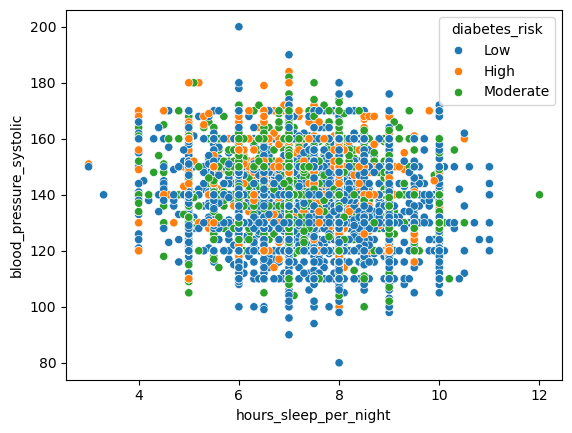

In [30]:
sns.scatterplot(data=df,x='hours_sleep_per_night',y='blood_pressure_systolic',hue='diabetes_risk')

In [57]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"]
)

pca_df["Cluster"] = clusters

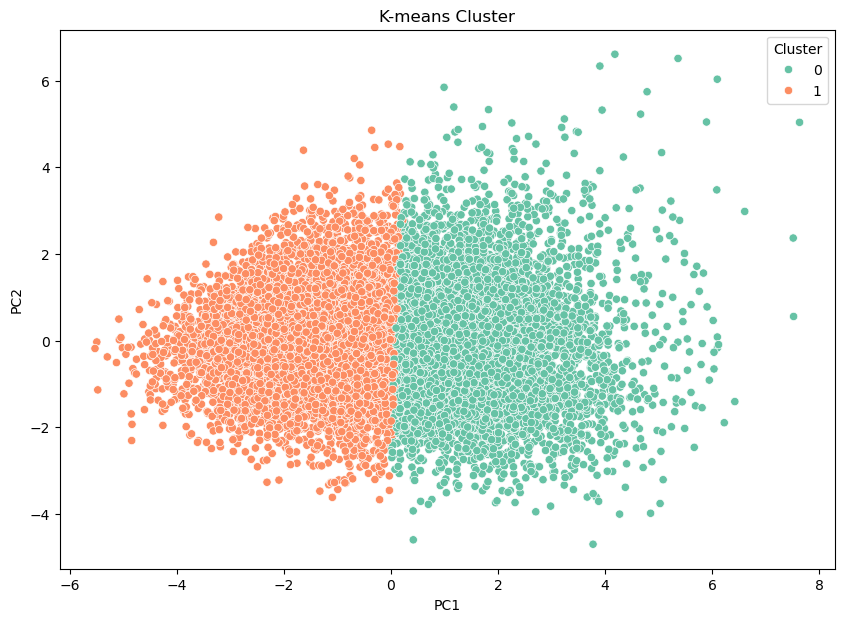

In [58]:
plt.figure(figsize=(10,7))
sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue='Cluster',
    palette='Set2'
)

plt.title("K-means Cluster")
plt.xlabel("PC1")
plt.ylabel("PC2")

plt.show()

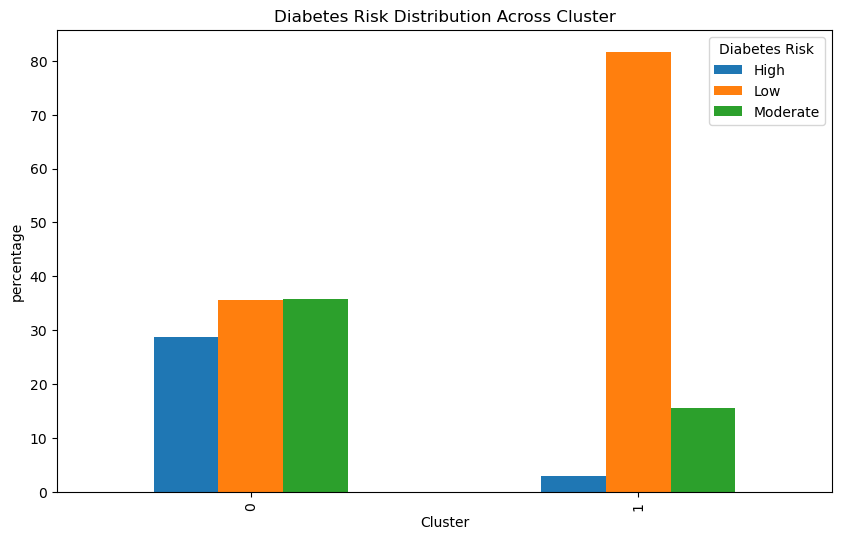

In [61]:
risk_table=pd.crosstab(
    df["Cluster"],
    df["diabetes_risk"],
    normalize="index"
)*100
risk_table.plot(kind="bar",figsize=(10,6))

plt.title("Diabetes Risk Distribution Across Cluster")
plt.xlabel("Cluster")
plt.ylabel("percentage")
plt.legend(title="Diabetes Risk")

plt.show()

In [72]:
sample = X_scaled[:1000]

In [75]:
linkage_matrix = linkage(
    sample,
    method="ward"
)

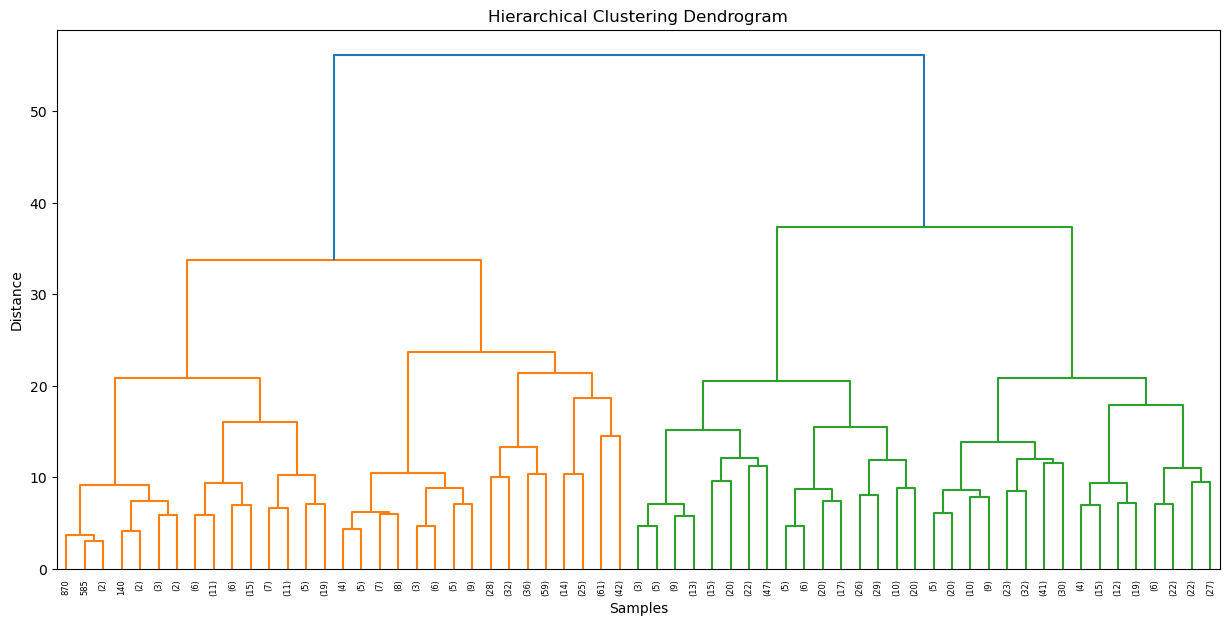

In [76]:
plt.figure(figsize=(15, 7))

dendrogram(
    linkage_matrix,
    truncate_mode="level",
    p=5
)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Samples")
plt.ylabel("Distance")

plt.show()

In [79]:
hierarchical = AgglomerativeClustering(
    n_clusters=optimal_k,
    linkage="ward"
)

hierarchical_labels = hierarchical.fit_predict(X_scaled)

In [80]:
kmeans_score = silhouette_score(
    X_scaled,
    clusters
)

hierarchical_score = silhouette_score(
    X_scaled,
    hierarchical_labels
)

print("K-Means Silhouette Score:", kmeans_score)
print("Hierarchical Silhouette Score:", hierarchical_score)

K-Means Silhouette Score: 0.15258716191464108
Hierarchical Silhouette Score: 0.10657202375701028


In [69]:
# x=df.iloc[:, 1:18]
# y=df['diabetes_risk']

In [70]:
# x

In [71]:
# y

In [34]:
# x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.3,random_state=0)

In [62]:
# x_train

In [63]:
# x_train.shape

In [64]:
# x_test.shape

In [68]:
# y_train

In [67]:
# df.describe()

In [66]:
# df.iloc[0:,10:16].corr()

In [65]:
# df.iloc[0:,10:16].cov()